# 01. Khám phá Dữ liệu & Làm sạch (EDA)
**Đề tài:** Dự đoán khả năng khách hàng hủy đặt phòng khách sạn (*Hotel Booking Demand*)  
**Nguồn dữ liệu:** Antonio, Almeida, & Nunes (2019) — `../data/raw/hotel_bookings.csv`

## 0. Đặt vấn đề & Giả định thời điểm dự đoán
- **Bài toán:** Phân loại nhị phân dự đoán biến mục tiêu `is_canceled` (`0` = Không hủy, `1` = Đã hủy).
- **Giả định thời điểm dự đoán:** Dự đoán **tại thời điểm xác nhận đặt phòng** (*Booking Confirmation*). Giả định này làm cơ sở phân biệt các biến có sẵn tại lúc dự đoán với các biến gây rò rỉ dữ liệu (*Direct Leakage* và *Temporal / Post-booking Leakage*).
- **Quy trình thực hiện trong Notebook:**
  1. **Basic EDA (`df_raw`):** Khảo sát cấu trúc, kiểu biến, thống kê mô tả, dữ liệu thiếu, bất thường, ngoại lai và kiểm tra rò rỉ dữ liệu (tuyệt đối không sửa đổi `df_raw`).
  2. **Data Cleaning (`df_clean`):** Áp dụng các quy tắc làm sạch xác định trước, kiểm tra trùng lặp / fingerprint cơ bản và đối chiếu trước–sau.
  3. **Main EDA (`df_eda`):** Thực hiện toàn bộ phân tích biến mục tiêu, đơn biến, hai biến, tương quan và xu hướng thời gian trên dữ liệu đã làm sạch.
  4. **Kết luận & Định hướng Preprocessing:** Tổng hợp phát hiện chính và gợi ý đồng bộ với Notebook 02.

## 1. Basic EDA (Khám phá & Kiểm toán Dữ liệu Gốc)
### 1.1 Khởi tạo thư viện và nạp dữ liệu thô (`df_raw`)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình biểu đồ chuẩn báo cáo học thuật (300 DPI, hỗ trợ tiếng Việt)
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RAW_PATH = Path("../data/raw/hotel_bookings.csv")
FIG_DIR = Path("../eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_canceled"
PALETTE = {0: "#2a9d8f", 1: "#e76f51"}

df_raw = pd.read_csv(RAW_PATH)
print(f"Kích thước dữ liệu gốc (df_raw): {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
display(df_raw.head(5))
print("\n=== Thông tin cấu trúc df_raw.info() ===")
df_raw.info()

Kích thước dữ liệu gốc (df_raw): 119,390 dòng x 32 cột


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



=== Thông tin cấu trúc df_raw.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null

In [2]:
# 1.2 Thống kê mô tả và phân loại kiểu biến
print("=== Thống kê mô tả các biến số ===")
display(df_raw.describe().T.round(2))

cat_cols_raw = df_raw.select_dtypes(include=["object", "string", "category"]).columns.tolist()
print("\n=== Thống kê mô tả các biến chuỗi / phân loại ===")
display(df_raw[cat_cols_raw].describe().T)

# Phân nhóm đặc trưng theo bản chất dữ liệu
feature_groups = pd.DataFrame([
    {"Nhóm biến": "Biến mục tiêu (Target)", "Các cột": "is_canceled", "Ghi chú": "Nhị phân: 0 (Không hủy), 1 (Đã hủy)"},
    {"Nhóm biến": "Số liên tục (Continuous)", "Các cột": "adr", "Ghi chú": "Giá phòng trung bình/đêm (EUR)"},
    {"Nhóm biến": "Số đếm (Count)", "Các cột": "lead_time, stays_in_weekend_nights, stays_in_week_nights, adults, children, babies, previous_cancellations, previous_bookings_not_canceled, booking_changes, days_in_waiting_list, required_car_parking_spaces, total_of_special_requests", "Ghi chú": "Giá trị nguyên không âm"},
    {"Nhóm biến": "Nhị phân (Binary)", "Các cột": "is_repeated_guest", "Ghi chú": "0 / 1"},
    {"Nhóm biến": "Thành phần ngày (Date components)", "Các cột": "arrival_date_year, arrival_date_month, arrival_date_week_number, arrival_date_day_of_month", "Ghi chú": "Ngày nhận phòng dự kiến (không phải ngày đặt)"},
    {"Nhóm biến": "Phân loại danh nghĩa (Nominal)", "Các cột": "hotel, meal, country, market_segment, distribution_channel, reserved_room_type, assigned_room_type, deposit_type, customer_type", "Ghi chú": "Biến phân loại chuỗi"},
    {"Nhóm biến": "Mã định danh (Identifier-like)", "Các cột": "agent, company", "Ghi chú": "Lưu dạng số nhưng thực chất là mã định danh phân loại, không phải đại lượng liên tục"},
    {"Nhóm biến": "Trạng thái kết quả (Status / Leakage)", "Các cột": "reservation_status, reservation_status_date", "Ghi chú": "Chỉ biết sau khi đơn kết thúc"},
])
print("\n=== Phân loại kiểu biến (Feature Types) ===")
display(feature_groups)

=== Thống kê mô tả các biến số ===


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0



=== Thống kê mô tả các biến chuỗi / phân loại ===


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613



=== Phân loại kiểu biến (Feature Types) ===


,Nhóm biến,Các cột,Ghi chú
0,Biến mục tiêu (Target),is_canceled,"Nhị phân: 0 (Không hủy), 1 (Đã hủy)"
1,Số liên tục (Continuous),adr,Giá phòng trung bình/đêm (EUR)
2,Số đếm (Count),"lead_time, stays_in_weekend_nights, stays_in_w...",Giá trị nguyên không âm
3,Nhị phân (Binary),is_repeated_guest,0 / 1
4,Thành phần ngày (Date components),"arrival_date_year, arrival_date_month, arrival...",Ngày nhận phòng dự kiến (không phải ngày đặt)
5,Phân loại danh nghĩa (Nominal),"hotel, meal, country, market_segment, distribu...",Biến phân loại chuỗi
6,Mã định danh (Identifier-like),"agent, company",Lưu dạng số nhưng thực chất là mã định danh ph...
7,Trạng thái kết quả (Status / Leakage),"reservation_status, reservation_status_date",Chỉ biết sau khi đơn kết thúc


**Nhận xét tổng quan:**
- Tập dữ liệu gốc gồm đầy đủ các đặc trưng mô tả thời gian nhận phòng, thời lượng lưu trú, cơ cấu khách, kênh đặt phòng, lịch sử giao dịch và trạng thái đặt phòng.
- Hai cột `agent` và `company` được lưu ở kiểu số thực (`float64`) do chứa giá trị thiếu, nhưng bản chất là **mã định danh phân loại** nên không được diễn giải hay tính tương quan như biến liên tục.

In [3]:
# 1.3 Kiểm tra dữ liệu thiếu, bất thường, ngày hợp lệ và ngoại lai (IQR)
month_map = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}

# 1) Bảng dữ liệu thiếu
missing_raw = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "nunique": df_raw.nunique(dropna=True),
})
missing_raw = missing_raw[missing_raw["missing_count"] > 0].sort_values("missing_count", ascending=False)
print("=== Các cột có dữ liệu thiếu (df_raw) ===")
display(missing_raw)

# 2) Kiểm tra tính hợp lệ của ngày nhận phòng và giá trị bất thường
arrival_raw = pd.to_datetime(
    pd.DataFrame({
        "year": df_raw["arrival_date_year"],
        "month": df_raw["arrival_date_month"].map(month_map),
        "day": df_raw["arrival_date_day_of_month"],
    }),
    errors="coerce",
)
# Dùng min_count=3 để không ép children=NA thành 0 khi kiểm tra tổng khách bằng 0
guests_raw = df_raw[["adults", "children", "babies"]].sum(axis=1, min_count=3)
nights_raw = df_raw["stays_in_weekend_nights"] + df_raw["stays_in_week_nights"]
non_neg_cols = [
    "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests",
]
neg_other_count = sum(int((df_raw[c] < 0).sum()) for c in non_neg_cols)
undef_counts = {c: int((df_raw[c] == "Undefined").sum()) for c in cat_cols_raw if (df_raw[c] == "Undefined").sum() > 0}

anomaly_table = pd.DataFrame([
    {"Quy tắc kiểm tra": "Target thiếu hoặc ngoài {0, 1}", "Số dòng": int((~df_raw[TARGET].isin([0, 1])).sum()), "Tỷ lệ (%)": round((~df_raw[TARGET].isin([0, 1])).mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Ngày đến (arrival_date) không hợp lệ", "Số dòng": int(arrival_raw.isna().sum()), "Tỷ lệ (%)": round(arrival_raw.isna().mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Tổng khách = 0 (biết đủ 3 thành phần)", "Số dòng": int(guests_raw.eq(0).sum()), "Tỷ lệ (%)": round(guests_raw.eq(0).mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Dòng có children = NA (không kết luận 0 khách)", "Số dòng": int(df_raw["children"].isna().sum()), "Tỷ lệ (%)": round(df_raw["children"].isna().mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Các cột đếm / lead_time < 0", "Số dòng": neg_other_count, "Tỷ lệ (%)": round(neg_other_count / len(df_raw) * 100, 4)},
    {"Quy tắc kiểm tra": "Giá phòng ADR < 0", "Số dòng": int((df_raw["adr"] < 0).sum()), "Tỷ lệ (%)": round((df_raw["adr"] < 0).mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Giá phòng ADR > 1000 (ngoại lai cực đại)", "Số dòng": int((df_raw["adr"] > 1000).sum()), "Tỷ lệ (%)": round((df_raw["adr"] > 1000).mean() * 100, 4)},
    {"Quy tắc kiểm tra": "Tổng đêm lưu trú = 0 (có thể là day-use)", "Số dòng": int(nights_raw.eq(0).sum()), "Tỷ lệ (%)": round(nights_raw.eq(0).mean() * 100, 4)},
])
print(f"\nKhoảng thời gian nhận phòng hợp lệ: {arrival_raw.min().date()} -> {arrival_raw.max().date()} ({arrival_raw.dt.to_period('M').nunique()} tháng)")
print("Các cột phân loại chứa giá trị 'Undefined':", undef_counts)
display(anomaly_table)

print("\nBản ghi minh họa ADR < 0 và ADR > 1000:")
display(df_raw.loc[(df_raw["adr"] < 0) | (df_raw["adr"] > 1000), ["hotel", "arrival_date_year", "arrival_date_month", "adults", "adr", TARGET]])

# 3) Nhận diện ngoại lai bằng Quantile & IQR (chỉ audit, không tự động xóa)
iqr_rows = []
for col_name, series in [("lead_time", df_raw["lead_time"]), ("adr", df_raw["adr"]), ("total_nights", nights_raw)]:
    q1, med, q3 = series.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    n_out = int(((series < lower) | (series > upper)).sum())
    iqr_rows.append({
        "Biến": col_name, "Min": round(float(series.min()), 2), "Q1": round(float(q1), 2),
        "Median": round(float(med), 2), "Q3": round(float(q3), 2), "P99": round(float(series.quantile(0.99)), 2),
        "Max": round(float(series.max()), 2), "Số điểm ngoài 1.5*IQR": n_out, "Tỷ lệ ngoài IQR (%)": round(n_out / len(df_raw) * 100, 2),
    })
print("\n=== Kiểm tra phân phối & ngoại lai theo quy tắc IQR (không tự động loại) ===")
display(pd.DataFrame(iqr_rows))

=== Các cột có dữ liệu thiếu (df_raw) ===


,missing_count,missing_pct,nunique
company,112593,94.307,352
agent,16340,13.686,333
country,488,0.409,177
children,4,0.003,5



Khoảng thời gian nhận phòng hợp lệ: 2015-07-01 -> 2017-08-31 (26 tháng)
Các cột phân loại chứa giá trị 'Undefined': {'meal': 1169, 'market_segment': 2, 'distribution_channel': 5}


,Quy tắc kiểm tra,Số dòng,Tỷ lệ (%)
0,"Target thiếu hoặc ngoài {0, 1}",0,0.0000
1,Ngày đến (arrival_date) không hợp lệ,0,0.0000
2,Tổng khách = 0 (biết đủ 3 thành phần),180,0.1508
3,Dòng có children = NA (không kết luận 0 khách),4,0.0034
4,Các cột đếm / lead_time < 0,0,0.0000
5,Giá phòng ADR < 0,1,0.0008
6,Giá phòng ADR > 1000 (ngoại lai cực đại),1,0.0008
7,Tổng đêm lưu trú = 0 (có thể là day-use),715,0.5989



Bản ghi minh họa ADR < 0 và ADR > 1000:


,hotel,arrival_date_year,arrival_date_month,adults,adr,is_canceled
14969,Resort Hotel,2017,March,2,-6.38,0
48515,City Hotel,2016,March,2,5400.00,1



=== Kiểm tra phân phối & ngoại lai theo quy tắc IQR (không tự động loại) ===


,Biến,Min,Q1,Median,Q3,P99,Max,Số điểm ngoài 1.5*IQR,Tỷ lệ ngoài IQR (%)
0,lead_time,0.00,18.00,69.00,160.0,444.0,737.0,3005,2.52
1,adr,-6.38,69.29,94.58,126.0,252.0,5400.0,3793,3.18
2,total_nights,0.00,2.00,3.00,4.0,14.0,69.0,5257,4.40


In [4]:
# 1.4 Kiểm tra Data Leakage trọng tâm (theo giả định dự đoán lúc xác nhận đặt phòng)
print("=== Kiểm chứng Direct Leakage: reservation_status vs is_canceled ===")
display(pd.crosstab(df_raw["reservation_status"], df_raw[TARGET], margins=True))

leakage_audit = pd.DataFrame([
    {
        "Biến": "reservation_status, reservation_status_date",
        "Loại rủi ro": "Direct Leakage (Rò rỉ trực tiếp)",
        "Phạm vi EDA": "Loại khỏi Main EDA",
        "Phạm vi Modeling": "Bắt buộc loại bỏ",
        "Lý do": "Khớp 100% với nhãn is_canceled; chỉ được ghi nhận sau khi đơn hoàn tất hoặc bị hủy.",
    },
    {
        "Biến": "assigned_room_type (và biến dẫn xuất room_type_changed)",
        "Loại rủi ro": "Temporal / Post-booking Leakage",
        "Phạm vi EDA": "Không đưa room_type_changed vào biểu đồ chính",
        "Phạm vi Modeling": "Nên loại nếu dự đoán lúc xác nhận đặt phòng",
        "Lý do": "Phòng thực nhận có thể thay đổi sát thời điểm check-in, không chắc chắn biết tại lúc đặt phòng.",
    },
    {
        "Biến": "booking_changes, days_in_waiting_list",
        "Loại rủi ro": "Temporal / Post-booking Leakage",
        "Phạm vi EDA": "Không xếp hạng như ứng viên đầu vào chính",
        "Phạm vi Modeling": "Nên loại trong chế độ dự đoán lúc đặt phòng",
        "Lý do": "Phản ánh các chỉnh sửa hoặc thời gian chờ phát sinh sau thời điểm đặt phòng ban đầu.",
    },
    {
        "Biến": "deposit_type, adr, country, total_of_special_requests, required_car_parking_spaces",
        "Loại rủi ro": "Cần lưu ý ngữ cảnh dữ liệu",
        "Phạm vi EDA": "Giữ để phân tích trong Main EDA",
        "Phạm vi Modeling": "Cần xác minh mốc ghi nhận với hệ thống nguồn",
        "Lý do": "Chưa có bằng chứng khẳng định chắc chắn gây leakage; giữ để khảo sát nhưng cần kiểm tra quy trình ghi nhận thực tế.",
    },
])
print("\n=== Tổng hợp kiểm tra rủi ro Data Leakage ===")
display(leakage_audit)

=== Kiểm chứng Direct Leakage: reservation_status vs is_canceled ===


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390



=== Tổng hợp kiểm tra rủi ro Data Leakage ===


,Biến,Loại rủi ro,Phạm vi EDA,Phạm vi Modeling,Lý do
0,"reservation_status, reservation_status_date",Direct Leakage (Rò rỉ trực tiếp),Loại khỏi Main EDA,Bắt buộc loại bỏ,Khớp 100% với nhãn is_canceled; chỉ được ghi n...
1,assigned_room_type (và biến dẫn xuất room_type...,Temporal / Post-booking Leakage,Không đưa room_type_changed vào biểu đồ chính,Nên loại nếu dự đoán lúc xác nhận đặt phòng,Phòng thực nhận có thể thay đổi sát thời điểm ...
2,"booking_changes, days_in_waiting_list",Temporal / Post-booking Leakage,Không xếp hạng như ứng viên đầu vào chính,Nên loại trong chế độ dự đoán lúc đặt phòng,Phản ánh các chỉnh sửa hoặc thời gian chờ phát...
3,"deposit_type, adr, country, total_of_special_r...",Cần lưu ý ngữ cảnh dữ liệu,Giữ để phân tích trong Main EDA,Cần xác minh mốc ghi nhận với hệ thống nguồn,Chưa có bằng chứng khẳng định chắc chắn gây le...


**Nhận xét Basic EDA:**
1. **Direct Leakage được xác minh tuyệt đối:** Mọi dòng `Check-Out` đều có `is_canceled = 0`, mọi dòng `Canceled` hoặc `No-Show` đều có `is_canceled = 1`. Do đó `reservation_status` và `reservation_status_date` bắt buộc phải loại khỏi mọi phân tích chính và mô hình.
2. **Phân tách rõ phạm vi EDA và phạm vi Modeling:** Các biến có khả năng cập nhật sau đặt phòng (`assigned_room_type`, `booking_changes`, `days_in_waiting_list`) không được dùng làm ứng viên mô hình ở mốc xác nhận đặt phòng; trong khi các biến chưa có bằng chứng chắc chắn gây leakage (`deposit_type`, `adr`, `country`, `total_of_special_requests`, `required_car_parking_spaces`) vẫn được khảo sát khách quan trong Main EDA kèm lưu ý cần xác minh thời điểm ghi nhận.
3. **Chất lượng dữ liệu:** `is_canceled` hợp lệ 100%, ngày đến hợp lệ trên cả 26 tháng (`07/2015 – 08/2017`). Ngoại lai theo IQR xuất hiện nhiều ở biến lệch phải (`lead_time`, `adr`, `total_nights`) nên không được xóa máy móc theo ngưỡng IQR.

## 2. Data Cleaning (Làm sạch Dữ liệu & Kiểm tra Trước/Sau)
### 2.1 Chính sách làm sạch dữ liệu (áp dụng trên bản sao `df_clean`, không dùng nhãn để lọc dòng)
| Vấn đề phát hiện | Quyết định | Lý do ngắn gọn |
|---|---|---|
| Tổng khách bằng `0` (`adults + children + babies == 0`, biết đủ 3 cột) | **Loại bỏ** | Đơn đặt phòng không có khách là bản ghi bất hợp lệ; không dùng `fillna(0)` cho 4 dòng `children = NA`. |
| `adr < 0` | **Loại bỏ** | Giá phòng trung bình âm nằm ngoài miền giá trị hợp lệ của bài toán. |
| `adr > 1000` (1 bản ghi `adr = 5400`) | **Giữ lại** | Không tự xóa ngoại lai chỉ vì vượt ngưỡng; chỉ giới hạn phạm vi hiển thị khi vẽ biểu đồ có chú thích. |
| Tổng đêm lưu trú bằng `0` | **Giữ lại** | Có thể là đơn đặt phòng trong ngày (*day-use*) hợp lệ. |
| Giá trị thiếu (`children`, `country`, `agent`, `company`) | **Trì hoãn (Deferred)** | Giữ nguyên `NA` ở giai đoạn EDA; xử lý imputation/encoding bên trong pipeline huấn luyện (Notebook 02/03) để tránh rò rỉ dữ liệu. |
| Bản ghi trùng lặp (*Duplicates*) | **Giữ mặc định + Kiểm tra độ nhạy** | Dữ liệu không có mã `booking_id` để chứng minh các dòng giống nhau là cùng một giao dịch bị lặp lỗi hay nhiều phòng đặt giống nhau. |

In [5]:
# 2.2 Thực thi Data Cleaning trực tiếp (không mutate df_raw)
df_clean = df_raw.copy()

mask_zero_guests = df_clean[["adults", "children", "babies"]].sum(axis=1, min_count=3).eq(0).fillna(False)
mask_neg_adr = df_clean["adr"].lt(0).fillna(False)

n_raw = len(df_clean)
n_removed_guests = int(mask_zero_guests.sum())
df_clean = df_clean.loc[~mask_zero_guests].copy()

mask_neg_adr_after = df_clean["adr"].lt(0).fillna(False)
n_removed_neg_adr = int(mask_neg_adr_after.sum())
df_clean = df_clean.loc[~mask_neg_adr_after].reset_index(drop=True)

# Kiểm tra tính toàn vẹn cơ bản
assert len(df_clean) > 0, "df_clean không được rỗng!"
assert df_clean[TARGET].notna().all() and df_clean[TARGET].isin([0, 1]).all(), "Target không hợp lệ!"
assert n_raw - len(df_clean) == n_removed_guests + n_removed_neg_adr, "Số dòng loại bỏ không khớp!"

# Báo cáo Trước / Sau cleaning
raw_cancel_pct = df_raw[TARGET].mean() * 100
clean_cancel_pct = df_clean[TARGET].mean() * 100
diff_pp = clean_cancel_pct - raw_cancel_pct

cleaning_summary = pd.DataFrame([
    {"Bước xử lý": "Dữ liệu gốc (df_raw)", "Số dòng": n_raw, "Số dòng loại": 0, "Tỷ lệ hủy (%)": round(raw_cancel_pct, 2)},
    {"Bước xử lý": "Loại confirmed_zero_guests", "Số dòng": n_raw - n_removed_guests, "Số dòng loại": n_removed_guests, "Tỷ lệ hủy (%)": round(df_raw.loc[~mask_zero_guests, TARGET].mean() * 100, 2)},
    {"Bước xử lý": "Loại adr < 0 -> df_clean", "Số dòng": len(df_clean), "Số dòng loại": n_removed_neg_adr, "Tỷ lệ hủy (%)": round(clean_cancel_pct, 2)},
])
display(cleaning_summary)
print(f"Tổng số dòng loại bỏ: {n_raw - len(df_clean):,} ({(n_raw - len(df_clean))/n_raw*100:.3f}%) | Thay đổi tỷ lệ hủy: {diff_pp:+.3f} điểm phần trăm")

missing_after = df_clean.isna().sum()
print("\nCác cột còn giá trị thiếu trong df_clean (trì hoãn xử lý sang Notebook 02/03):")
display(missing_after[missing_after > 0].to_frame("missing_count_clean"))

,Bước xử lý,Số dòng,Số dòng loại,Tỷ lệ hủy (%)
0,Dữ liệu gốc (df_raw),119390,0,37.04
1,Loại confirmed_zero_guests,119210,180,37.08
2,Loại adr < 0 -> df_clean,119209,1,37.08


Tổng số dòng loại bỏ: 181 (0.152%) | Thay đổi tỷ lệ hủy: +0.035 điểm phần trăm

Các cột còn giá trị thiếu trong df_clean (trì hoãn xử lý sang Notebook 02/03):


,missing_count_clean
children,4
country,478
agent,16280
company,112441


Dòng trùng hoàn toàn trên df_raw: 31,994
Dòng trùng trên df_clean (bỏ 2 cột status): 32,238
Fingerprint trên 26 feature (không chứa target): 8,502 nhóm lặp, trong đó 302 nhóm có nhãn mâu thuẫn.


,Phiên bản dữ liệu,Số dòng,Không hủy (%),Đã hủy (%)
0,df_raw (Gốc),119390,62.96,37.04
1,df_clean (Chính — giữ duplicates),119209,62.92,37.08
2,df_dedup_candidate (So sánh độ nhạy),86971,72.69,27.31


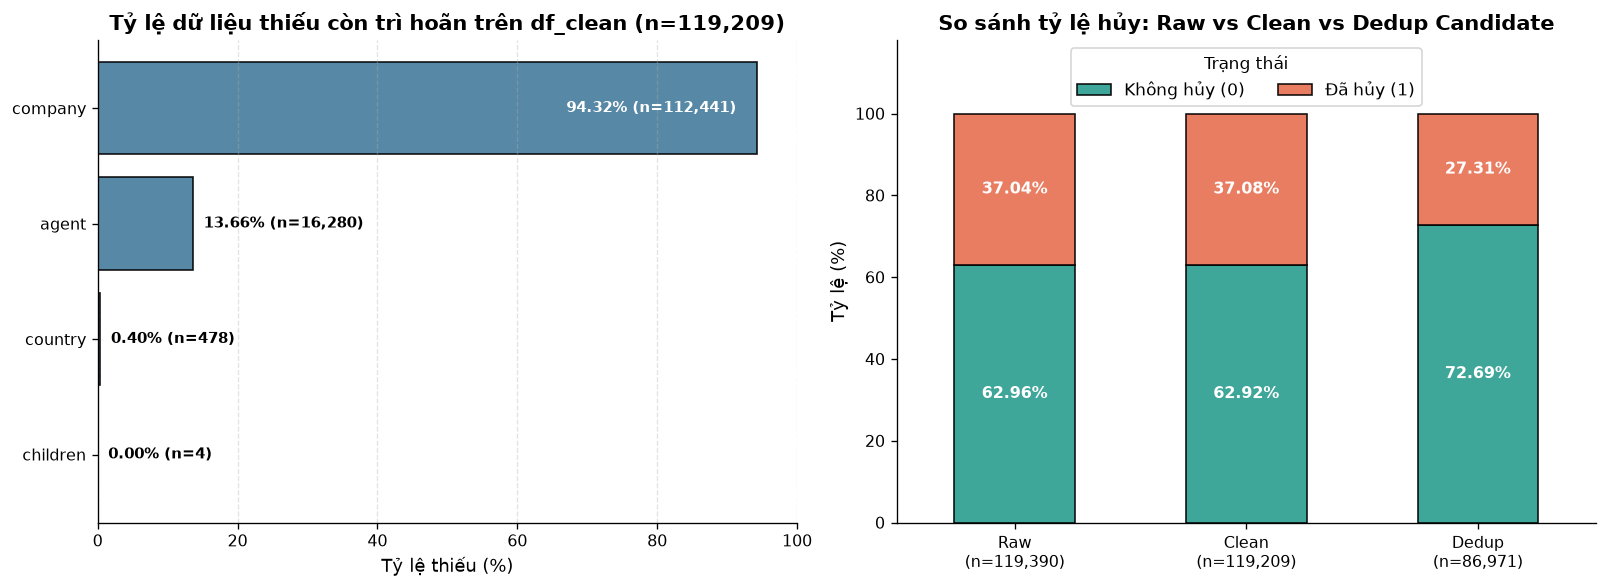

In [6]:
# 2.3 Kiểm tra Duplicates & Fingerprint cơ bản (không chứa target)
status_cols = ["reservation_status", "reservation_status_date"]
risky_post_cols = ["assigned_room_type", "booking_changes", "days_in_waiting_list"]
fp_cols = [c for c in df_clean.columns if c not in status_cols + risky_post_cols + [TARGET]]

raw_exact_dups = int(df_raw.duplicated().sum())
clean_no_status_dups = int(df_clean.drop(columns=status_cols).duplicated().sum())

# Fingerprint chỉ dựa trên feature (không chứa target) để phát hiện nhóm lặp & nhóm nhãn mâu thuẫn
fp = pd.util.hash_pandas_object(df_clean[fp_cols], index=False)
fp_stats = pd.DataFrame({"fp": fp, TARGET: df_clean[TARGET]}).groupby("fp")[TARGET].agg(["size", "nunique"])
n_repeated_groups = int(fp_stats["size"].gt(1).sum())
n_conflicting_groups = int(fp_stats["nunique"].gt(1).sum())

print(f"Dòng trùng hoàn toàn trên df_raw: {raw_exact_dups:,}")
print(f"Dòng trùng trên df_clean (bỏ 2 cột status): {clean_no_status_dups:,}")
print(f"Fingerprint trên {len(fp_cols)} feature (không chứa target): {n_repeated_groups:,} nhóm lặp, trong đó {n_conflicting_groups:,} nhóm có nhãn mâu thuẫn.")

# Bản ứng viên khử trùng lặp (chỉ dùng để so sánh độ nhạy, không mặc định thay df_clean)
df_dedup_candidate = df_clean.drop(columns=status_cols).drop_duplicates().reset_index(drop=True)

def target_pct(frame):
    return frame[TARGET].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

comp_table = pd.DataFrame([
    {"Phiên bản dữ liệu": "df_raw (Gốc)", "Số dòng": len(df_raw), "Không hủy (%)": round(target_pct(df_raw)[0], 2), "Đã hủy (%)": round(target_pct(df_raw)[1], 2)},
    {"Phiên bản dữ liệu": "df_clean (Chính — giữ duplicates)", "Số dòng": len(df_clean), "Không hủy (%)": round(target_pct(df_clean)[0], 2), "Đã hủy (%)": round(target_pct(df_clean)[1], 2)},
    {"Phiên bản dữ liệu": "df_dedup_candidate (So sánh độ nhạy)", "Số dòng": len(df_dedup_candidate), "Không hủy (%)": round(target_pct(df_dedup_candidate)[0], 2), "Đã hủy (%)": round(target_pct(df_dedup_candidate)[1], 2)},
])
display(comp_table)

# Biểu đồ 02: Tỷ lệ dữ liệu thiếu (df_clean) & So sánh phân phối nhãn Raw / Clean / Dedup
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

miss_plot = pd.DataFrame({
    "count": df_clean.isna().sum(),
    "pct": df_clean.isna().mean() * 100,
})
miss_plot = miss_plot[miss_plot["count"] > 0].sort_values("pct", ascending=True)
bars_m = axes[0].barh(miss_plot.index, miss_plot["pct"], color="#457b9d", edgecolor="black", alpha=0.9)
for bar, (_, row) in zip(bars_m, miss_plot.iterrows()):
    x_pos = row["pct"] - 3 if row["pct"] > 78 else row["pct"] + 1.5
    align = "right" if row["pct"] > 78 else "left"
    txt_color = "white" if row["pct"] > 78 else "black"
    axes[0].text(x_pos, bar.get_y() + bar.get_height() / 2,
                 f"{row['pct']:.2f}% (n={int(row['count']):,})",
                 va="center", ha=align, fontsize=9, fontweight="bold", color=txt_color)
axes[0].set_title(f"Tỷ lệ dữ liệu thiếu còn trì hoãn trên df_clean (n={len(df_clean):,})")
axes[0].set_xlabel("Tỷ lệ thiếu (%)")
axes[0].set_xlim(0, 100)
axes[0].grid(axis="x", linestyle="--", alpha=0.35)

plot_comp = pd.DataFrame({
    f"Raw\n(n={len(df_raw):,})": target_pct(df_raw),
    f"Clean\n(n={len(df_clean):,})": target_pct(df_clean),
    f"Dedup\n(n={len(df_dedup_candidate):,})": target_pct(df_dedup_candidate),
}).T
plot_comp.columns = ["Không hủy (0)", "Đã hủy (1)"]
plot_comp.plot(kind="bar", stacked=True, ax=axes[1], color=[PALETTE[0], PALETTE[1]], edgecolor="black", alpha=0.9, width=0.52)
for idx, (_, row) in enumerate(plot_comp.iterrows()):
    axes[1].text(idx, row["Không hủy (0)"] / 2, f"{row['Không hủy (0)']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    axes[1].text(idx, row["Không hủy (0)"] + row["Đã hủy (1)"] / 2, f"{row['Đã hủy (1)']:.2f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
axes[1].set_title("So sánh tỷ lệ hủy: Raw vs Clean vs Dedup Candidate")
axes[1].set_ylabel("Tỷ lệ (%)")
axes[1].set_xticklabels(plot_comp.index, rotation=0)
axes[1].set_ylim(0, 118)
axes[1].legend(title="Trạng thái", loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
fig.savefig(FIG_DIR / "02_missing_and_duplicates_audit.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét Data Cleaning & Duplicates:**
- Việc loại `confirmed_zero_guests` và `adr < 0` chỉ bỏ chưa tới `0,2%` số dòng và gần như giữ nguyên phân phối mục tiêu (chênh lệch khoảng `+0,04` điểm phần trăm).
- Tỷ lệ thiếu ở `company` và `agent` được giữ nguyên ở dạng `NA` để xử lý đúng quy trình trong bước tiền xử lý (tránh điền thiếu thủ công trước khi chia tập).
- Khi thử khử toàn bộ bản ghi trùng lặp (`df_dedup_candidate`), tỷ lệ hủy giảm gần `10` điểm phần trăm. Tuy nhiên do thiếu `booking_id` và xuất hiện nhiều nhóm giống feature nhưng khác nhãn (conflicting labels), không có đủ bằng chứng để kết luận toàn bộ dòng trùng là lỗi nhập liệu; vì vậy Main EDA sử dụng `df_clean` làm nguồn chính, đồng thời lưu ý cần thống nhất chính sách chống trùng mẫu giữa Train/Test khi xây dựng mô hình ở Notebook 02.

## 3. Main EDA (Phân tích Chính trên Dữ liệu Đã Làm Sạch)
Toàn bộ các phân tích và biểu đồ dưới đây sử dụng `df_eda` — được tạo trực tiếp từ `df_clean` sau khi loại bỏ 2 cột Direct Leakage (`reservation_status`, `reservation_status_date`).

### 3.1 Phân tích Biến mục tiêu (`is_canceled`) và Loại khách sạn

Nguồn Main EDA (df_eda): 119,209 dòng x 31 cột


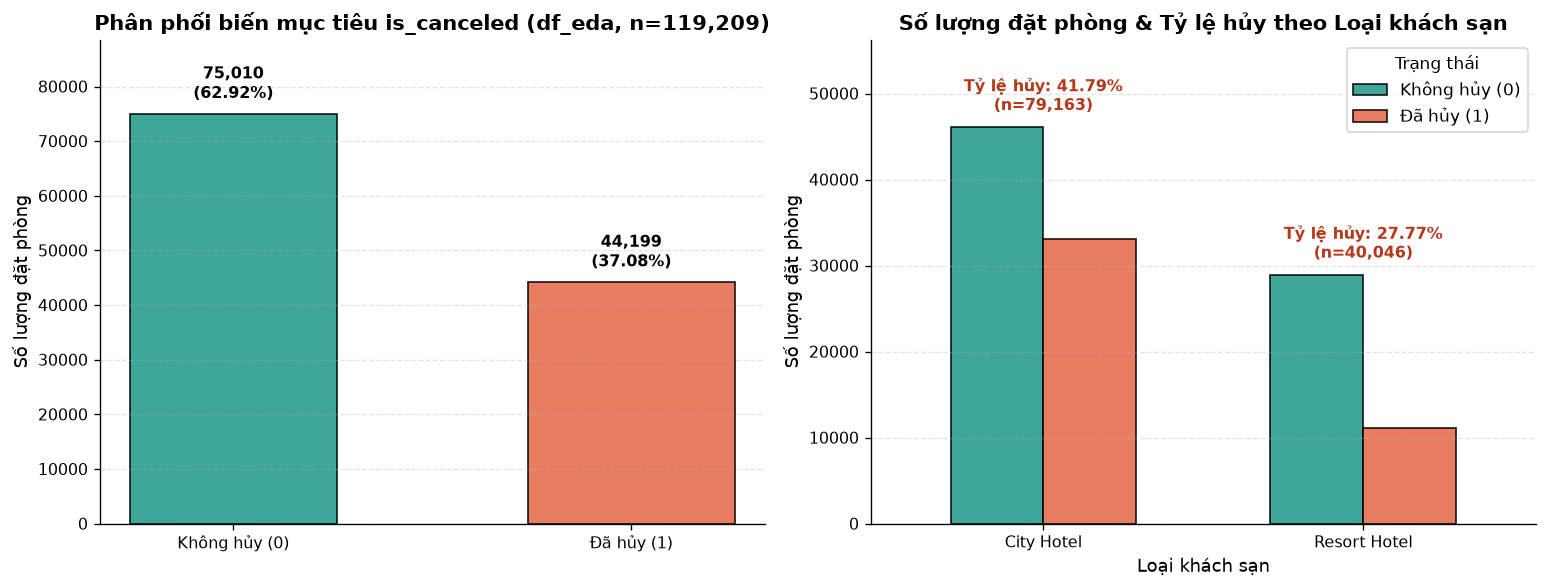

In [7]:
# Khởi tạo df_eda từ df_clean (tuyệt đối không quay lại df_raw)
df_eda = df_clean.drop(columns=status_cols).copy()
df_eda["total_nights"] = df_eda["stays_in_weekend_nights"] + df_eda["stays_in_week_nights"]
print(f"Nguồn Main EDA (df_eda): {df_eda.shape[0]:,} dòng x {df_eda.shape[1]} cột")

# Biểu đồ 01: Phân phối biến mục tiêu tổng thể & theo Loại khách sạn
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

target_counts = df_eda[TARGET].value_counts().reindex([0, 1], fill_value=0)
target_pcts = df_eda[TARGET].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
offset_0 = target_counts.max() * 0.025

bars = axes[0].bar(["Không hủy (0)", "Đã hủy (1)"], target_counts.values,
                   color=[PALETTE[0], PALETTE[1]], width=0.52, edgecolor="black", alpha=0.9)
for bar, count, pct in zip(bars, target_counts.values, target_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, count + offset_0,
                 f"{int(count):,}\n({pct:.2f}%)", ha="center", va="bottom", fontweight="bold", fontsize=9.8)
axes[0].set_title(f"Phân phối biến mục tiêu is_canceled (df_eda, n={len(df_eda):,})")
axes[0].set_ylabel("Số lượng đặt phòng")
axes[0].set_ylim(0, target_counts.max() * 1.18)
axes[0].grid(axis="y", linestyle="--", alpha=0.35)

hotel_counts = df_eda.groupby(["hotel", TARGET]).size().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
hotel_rates = df_eda.groupby("hotel")[TARGET].mean() * 100
offset_1 = hotel_counts.values.max() * 0.03

hotel_counts.plot(kind="bar", ax=axes[1], color=[PALETTE[0], PALETTE[1]], edgecolor="black", alpha=0.9, width=0.58)
axes[1].set_title("Số lượng đặt phòng & Tỷ lệ hủy theo Loại khách sạn")
axes[1].set_xlabel("Loại khách sạn")
axes[1].set_ylabel("Số lượng đặt phòng")
axes[1].set_xticklabels(hotel_counts.index, rotation=0)
axes[1].legend(["Không hủy (0)", "Đã hủy (1)"], title="Trạng thái")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)

for idx, hotel in enumerate(hotel_counts.index):
    ymax = hotel_counts.loc[hotel].max()
    axes[1].text(idx, ymax + offset_1, f"Tỷ lệ hủy: {hotel_rates.loc[hotel]:.2f}%\n(n={int(hotel_counts.loc[hotel].sum()):,})",
                 ha="center", va="bottom", fontweight="bold", color="#b5381b", fontsize=9.3)
axes[1].set_ylim(0, hotel_counts.values.max() * 1.22)

plt.tight_layout()
fig.savefig(FIG_DIR / "01_target_and_hotel_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét:**
- Biến mục tiêu `is_canceled` có mức mất cân bằng vừa phải (~63% không hủy so với ~37% đã hủy), nên khi đánh giá mô hình cần ưu tiên `ROC-AUC`, `PR-AUC` và `F1-Score` thay vì chỉ dựa vào `Accuracy`.
- `City Hotel` chiếm khoảng hai phần ba tổng lượng đặt phòng và có tỷ lệ hủy cao hơn rõ rệt so với `Resort Hotel`, cho thấy `hotel` là đặc trưng phân tách quan trọng.

### 3.2 Phân tích Đơn biến & Hai biến — Các Biến Số Trọng Tâm
Khảo sát phân phối và mối liên hệ với `is_canceled` trên 4 biến số chính: `lead_time`, `adr`, `total_nights` và `total_of_special_requests`. Lưu ý các giới hạn trục trong biểu đồ chỉ phục vụ hiển thị rõ ràng, **không** xóa dữ liệu khỏi `df_eda`.

=== So sánh Median, IQR và Mean của các biến số theo is_canceled (df_eda) ===


lead_time                   adr                total_nights       \
               median    IQR    mean median    IQR    mean       median  IQR   
is_canceled                                                                    
0                45.0  115.0   80.08   92.7  57.24  100.17          3.0  2.0   
1               113.0  165.0  144.89   96.3  54.87  105.02          3.0  2.0   

                  total_of_special_requests             
             mean                    median  IQR  mean  
is_canceled                                             
0            3.39                       1.0  1.0  0.71  
1            3.49                       0.0  0.0  0.33

,Panel,Mẫu hiển thị,Mẫu ngoài khung,Tỷ lệ ngoài khung (%)
0,lead_time <= 450,118103,1106,0.928
1,adr <= 400,119201,8,0.007
2,total_nights <= 10,117113,2096,1.758


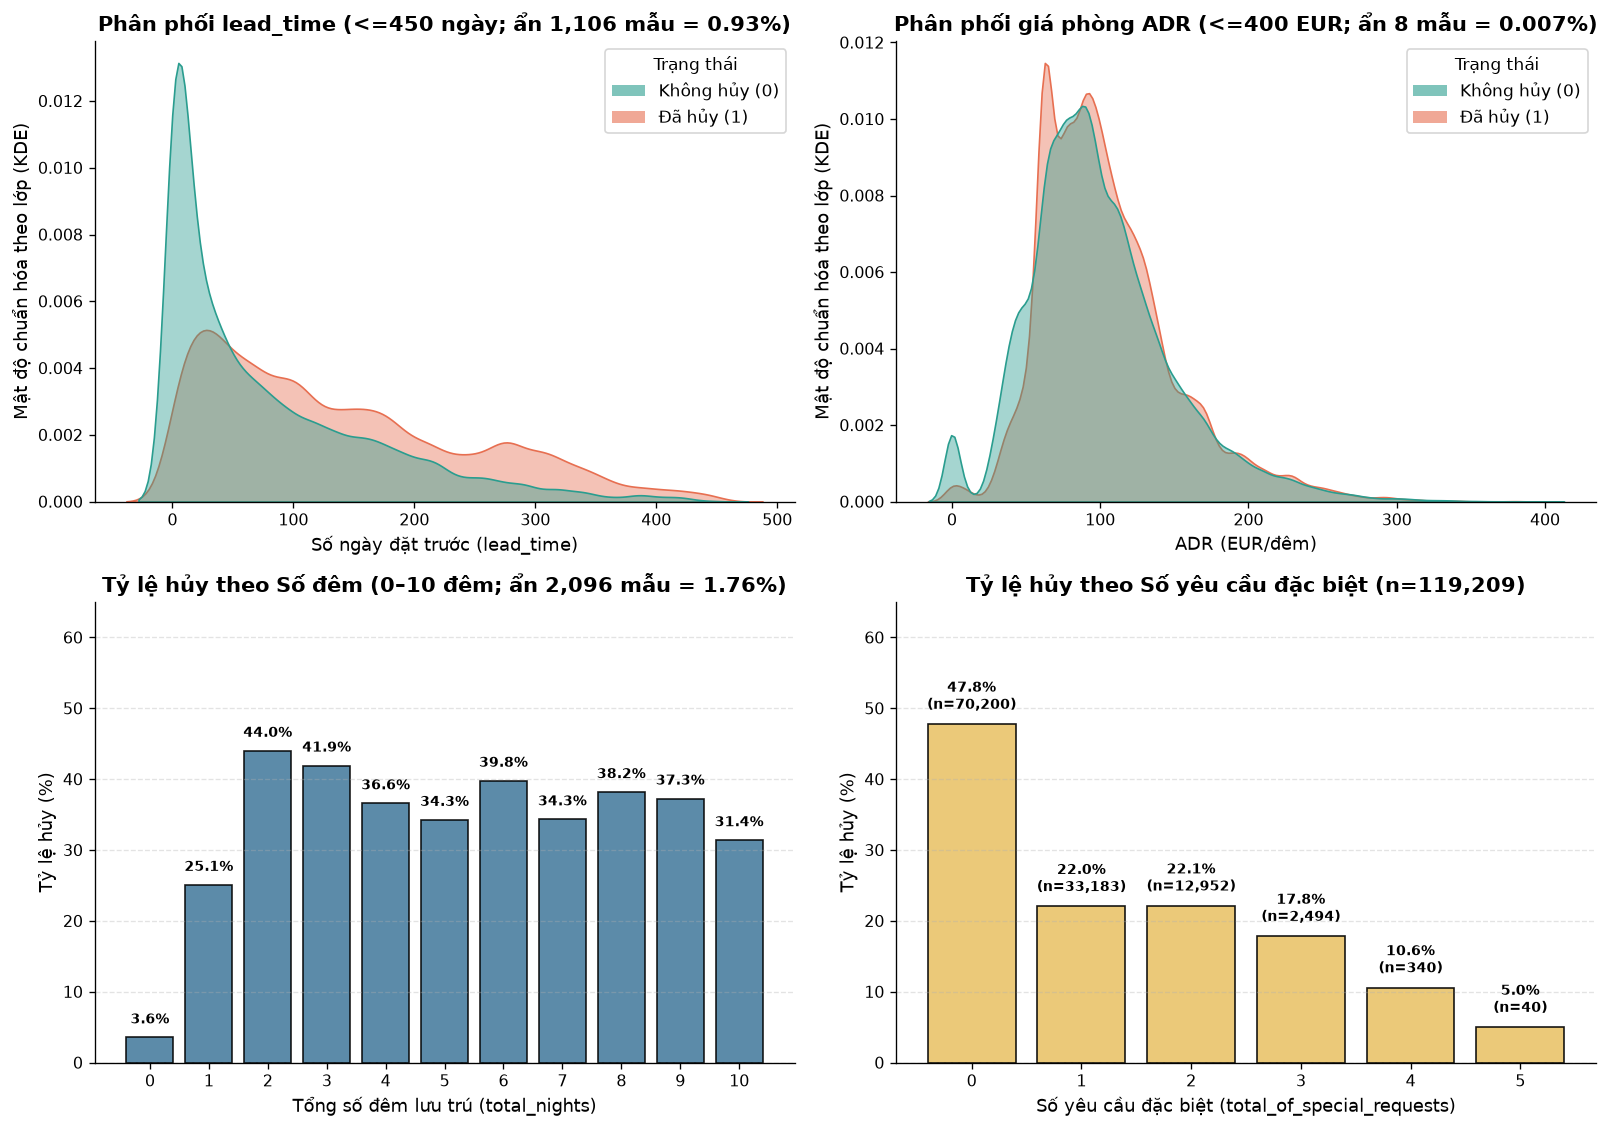

In [8]:
num_focus = ["lead_time", "adr", "total_nights", "total_of_special_requests"]

# Bảng thống kê Median và IQR theo trạng thái hủy
def iqr_func(s):
    return s.quantile(0.75) - s.quantile(0.25)

num_summary = df_eda.groupby(TARGET)[num_focus].agg(["median", iqr_func, "mean"]).round(2)
num_summary = num_summary.rename(columns={"iqr_func": "IQR"}, level=1)
print("=== So sánh Median, IQR và Mean của các biến số theo is_canceled (df_eda) ===")
display(num_summary)

# Tính số lượng & tỷ lệ mẫu nằm ngoài khung hiển thị (chỉ phục vụ trực quan hóa)
lead_excl = df_eda["lead_time"] > 450
adr_excl = df_eda["adr"] > 400
nights_excl = df_eda["total_nights"] > 10

excl_summary = pd.DataFrame([
    {"Panel": "lead_time <= 450", "Mẫu hiển thị": int((~lead_excl).sum()), "Mẫu ngoài khung": int(lead_excl.sum()), "Tỷ lệ ngoài khung (%)": round(lead_excl.mean() * 100, 3)},
    {"Panel": "adr <= 400", "Mẫu hiển thị": int((~adr_excl).sum()), "Mẫu ngoài khung": int(adr_excl.sum()), "Tỷ lệ ngoài khung (%)": round(adr_excl.mean() * 100, 3)},
    {"Panel": "total_nights <= 10", "Mẫu hiển thị": int((~nights_excl).sum()), "Mẫu ngoài khung": int(nights_excl.sum()), "Tỷ lệ ngoài khung (%)": round(nights_excl.mean() * 100, 3)},
])
display(excl_summary)

# Biểu đồ 04: Phân phối các biến số theo is_canceled
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5))

# Panel 1: Lead time KDE
sub_lead = df_eda.loc[~lead_excl]
sns.kdeplot(data=sub_lead, x="lead_time", hue=TARGET, hue_order=[0, 1], palette=PALETTE,
            fill=True, common_norm=False, alpha=0.42, ax=axes[0, 0])
axes[0, 0].set_title(f"Phân phối lead_time (<=450 ngày; ẩn {int(lead_excl.sum()):,} mẫu = {lead_excl.mean()*100:.2f}%)")
axes[0, 0].set_xlabel("Số ngày đặt trước (lead_time)")
axes[0, 0].set_ylabel("Mật độ chuẩn hóa theo lớp (KDE)")
from matplotlib.patches import Patch
kde_handles = [Patch(facecolor=PALETTE[0], alpha=0.6, label="Không hủy (0)"),
               Patch(facecolor=PALETTE[1], alpha=0.6, label="Đã hủy (1)")]
axes[0, 0].legend(handles=kde_handles, title="Trạng thái")

# Panel 2: ADR KDE
sub_adr = df_eda.loc[~adr_excl]
sns.kdeplot(data=sub_adr, x="adr", hue=TARGET, hue_order=[0, 1], palette=PALETTE,
            fill=True, common_norm=False, alpha=0.42, ax=axes[0, 1])
axes[0, 1].set_title(f"Phân phối giá phòng ADR (<=400 EUR; ẩn {int(adr_excl.sum()):,} mẫu = {adr_excl.mean()*100:.3f}%)")
axes[0, 1].set_xlabel("ADR (EUR/đêm)")
axes[0, 1].set_ylabel("Mật độ chuẩn hóa theo lớp (KDE)")
axes[0, 1].legend(handles=kde_handles, title="Trạng thái")

# Panel 3: Total nights cancellation rate
sub_nights = df_eda.loc[~nights_excl]
nights_stats = sub_nights.groupby("total_nights")[TARGET].agg(["count", "mean"])
bars_n = axes[1, 0].bar(nights_stats.index, nights_stats["mean"] * 100, color="#457b9d", edgecolor="black", alpha=0.88)
for bar, (_, row) in zip(bars_n, nights_stats.iterrows()):
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, row["mean"] * 100 + 1.5,
                    f"{row['mean']*100:.1f}%", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
axes[1, 0].set_title(f"Tỷ lệ hủy theo Số đêm (0–10 đêm; ẩn {int(nights_excl.sum()):,} mẫu = {nights_excl.mean()*100:.2f}%)")
axes[1, 0].set_xlabel("Tổng số đêm lưu trú (total_nights)")
axes[1, 0].set_ylabel("Tỷ lệ hủy (%)")
axes[1, 0].set_xticks(nights_stats.index)
axes[1, 0].set_ylim(0, 65)
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.35)

# Panel 4: Special requests cancellation rate
req_stats = df_eda.groupby("total_of_special_requests")[TARGET].agg(["count", "mean"])
bars_r = axes[1, 1].bar(req_stats.index.astype(str), req_stats["mean"] * 100, color="#e9c46a", edgecolor="black", alpha=0.9)
for bar, (_, row) in zip(bars_r, req_stats.iterrows()):
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2, row["mean"] * 100 + 1.5,
                    f"{row['mean']*100:.1f}%\n(n={int(row['count']):,})", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
axes[1, 1].set_title(f"Tỷ lệ hủy theo Số yêu cầu đặc biệt (n={len(df_eda):,})")
axes[1, 1].set_xlabel("Số yêu cầu đặc biệt (total_of_special_requests)")
axes[1, 1].set_ylabel("Tỷ lệ hủy (%)")
axes[1, 1].set_ylim(0, 65)
axes[1, 1].grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
fig.savefig(FIG_DIR / "04_numerical_distributions_by_target.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét nhóm biến số:**
- **`lead_time`:** Phân phối của nhóm đã hủy dịch chuyển mạnh về phía thời gian đặt trước dài hơn (trung vị cao hơn rõ rệt so với nhóm không hủy). Biểu đồ KDE dùng `common_norm=False` thể hiện mật độ chuẩn hóa riêng từng lớp để so sánh hình dạng phân phối.
- **`adr`:** Phân phối giá phòng giữa hai lớp chồng lấn khá nhiều, tuy nhiên nhóm hủy có trung vị `adr` hơi nhỉnh hơn; cần lưu ý 1 giá trị ngoại lai `adr = 5400` vẫn nằm trong `df_eda` nhưng được ẩn khỏi khung hiển thị `<= 400`.
- **`total_nights`:** Các đơn `0` đêm (*day-use*) có tỷ lệ hủy thấp hơn đáng kể so với đơn lưu trú từ 1–10 đêm.
- **`total_of_special_requests`:** Tỷ lệ hủy giảm đơn điệu rất rõ khi số lượng yêu cầu đặc biệt tăng từ `0` lên `3+` (lưu ý nhóm có `5` yêu cầu đặc biệt có cỡ mẫu nhỏ).

### 3.3 Phân tích Đơn biến & Hai biến — Các Biến Phân Loại Trọng Tâm
Khảo sát tỷ lệ hủy kèm cỡ mẫu `n` trên 4 biến phân loại chính (`deposit_type`, `market_segment`, `customer_type`, `reserved_room_type`). Biến `room_type_changed` không đưa vào phần này do phụ thuộc vào `assigned_room_type` có rủi ro rò rỉ thời gian. Các nhóm có cỡ mẫu nhỏ (`n < 30`) được đánh dấu `(*)` để tránh diễn giải quá mức.

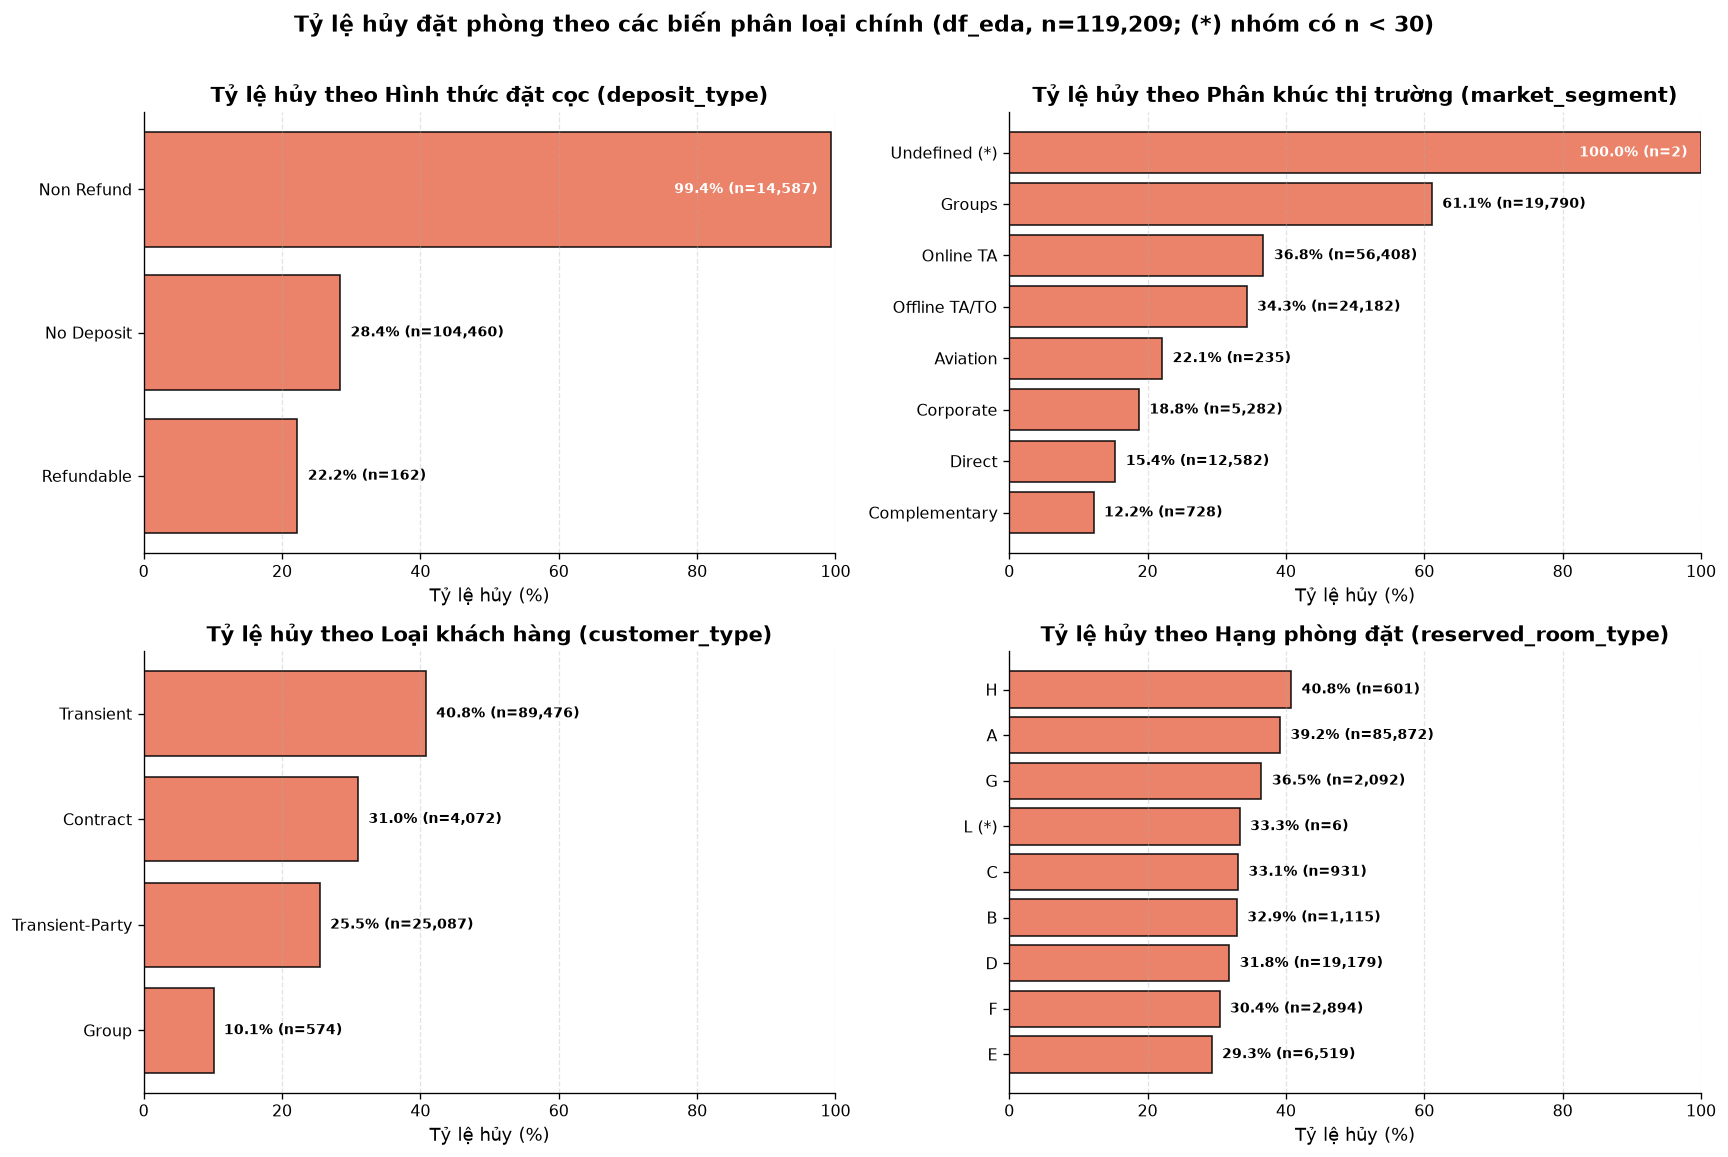

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.5))

cat_panels = [
    ("deposit_type", "Tỷ lệ hủy theo Hình thức đặt cọc (deposit_type)", axes[0, 0]),
    ("market_segment", "Tỷ lệ hủy theo Phân khúc thị trường (market_segment)", axes[0, 1]),
    ("customer_type", "Tỷ lệ hủy theo Loại khách hàng (customer_type)", axes[1, 0]),
    ("reserved_room_type", "Tỷ lệ hủy theo Hạng phòng đặt (reserved_room_type)", axes[1, 1]),
]

for col, title, ax in cat_panels:
    stats = df_eda.groupby(col)[TARGET].agg(["count", "mean"]).sort_values("mean", ascending=True)
    stats["pct"] = stats["mean"] * 100
    labels = [f"{cat} (*)" if cnt < 30 else str(cat) for cat, cnt in zip(stats.index, stats["count"])]
    bars = ax.barh(labels, stats["pct"], color="#e76f51", edgecolor="black", alpha=0.86)
    for bar, (_, row) in zip(bars, stats.iterrows()):
        pct_val = row["pct"]
        text_str = f"{pct_val:.1f}% (n={int(row['count']):,})"
        if pct_val > 72:
            ax.text(pct_val - 2.0, bar.get_y() + bar.get_height() / 2, text_str,
                    va="center", ha="right", fontsize=8.5, fontweight="bold", color="white")
        else:
            ax.text(pct_val + 1.5, bar.get_y() + bar.get_height() / 2, text_str,
                    va="center", ha="left", fontsize=8.5, fontweight="bold", color="black")
    ax.set_title(title)
    ax.set_xlabel("Tỷ lệ hủy (%)")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", linestyle="--", alpha=0.35)

fig.suptitle(f"Tỷ lệ hủy đặt phòng theo các biến phân loại chính (df_eda, n={len(df_eda):,}; (*) nhóm có n < 30)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(FIG_DIR / "05_categorical_cancellation_rates.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét nhóm biến phân loại:**
- **`deposit_type`:** Nhóm `Non Refund` ghi nhận tỷ lệ hủy rất cao (~99,4%) trên dữ liệu lịch sử — ngược với trực giác thông thường về đặt cọc không hoàn lại. Dữ liệu bảng hiện tại không đủ bằng chứng để khẳng định nguyên nhân nghiệp vụ cụ thể; đây là hiện tượng bất thường cần được xác minh lại định nghĩa và thời điểm ghi nhận từ nguồn hệ thống khách sạn trước khi đưa vào vận hành thực tế.
- **`market_segment` & `customer_type`:** Phân khúc `Groups` và `Online TA` có tỷ lệ hủy cao hơn rõ rệt so với `Direct` và `Corporate`; khách `Transient` hủy nhiều hơn `Transient-Party`. Các nhóm có cỡ mẫu rất nhỏ (`Undefined` ở `market_segment` với `n=2`, hạng phòng `L` ở `reserved_room_type` với `n=6`) được gắn dấu `(*)` vì cỡ mẫu nhỏ không đủ tin cậy để khái quát.
- **`reserved_room_type`:** Các hạng phòng phổ biến (`A`, `D`, `E`, `F`, `G`) có sự phân hóa tỷ lệ hủy nhất định, trong đó hạng phòng `A` (chiếm số lượng lớn nhất) có tỷ lệ hủy cao hơn nhiều hạng phòng khác.

### 3.4 Phân tích Tương quan (Spearman Correlation)
Sử dụng hệ số tương quan hạng Spearman (phù hợp với biến lệch phải và có ngoại lai) trên các biến số của `df_eda` (không bao gồm 2 cột `booking_changes`, `days_in_waiting_list` có rủi ro cập nhật sau đặt phòng và không đưa biến mã định danh `agent`, `company`). Thang màu giữ chuẩn `[-1, 1]` để phản ánh đúng cường độ tương quan.

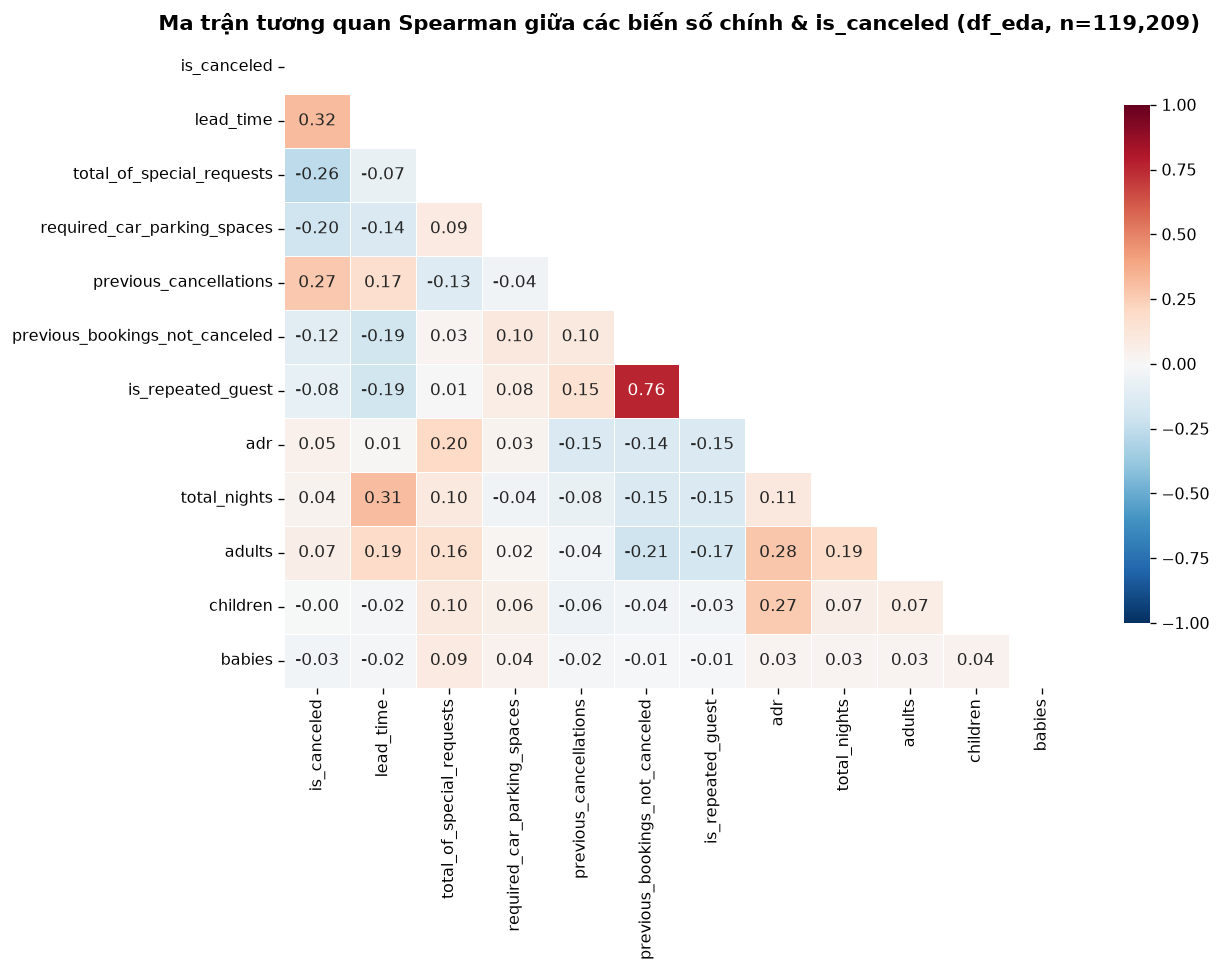

Xếp hạng tương quan Spearman với is_canceled:


,spearman_corr
lead_time,0.3165
previous_cancellations,0.2703
total_of_special_requests,-0.2587
required_car_parking_spaces,-0.1976
previous_bookings_not_canceled,-0.1154
is_repeated_guest,-0.0837
adults,0.0657
adr,0.0499
total_nights,0.0368
babies,-0.0344


In [10]:
num_cols_corr = [
    TARGET, "lead_time", "total_of_special_requests", "required_car_parking_spaces",
    "previous_cancellations", "previous_bookings_not_canceled", "is_repeated_guest",
    "adr", "total_nights", "adults", "children", "babies",
]
# Đảm bảo không có cột hằng số trước khi tính tương quan
valid_corr_cols = [c for c in num_cols_corr if df_eda[c].nunique(dropna=True) > 1]
corr_mat = df_eda[valid_corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10.8, 8.2))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8}
)
ax.set_title(f"Ma trận tương quan Spearman giữa các biến số chính & is_canceled (df_eda, n={len(df_eda):,})")
plt.tight_layout()
fig.savefig(FIG_DIR / "06_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Xếp hạng tương quan Spearman với is_canceled:")
display(corr_mat[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("spearman_corr").round(4))

**Nhận xét tương quan:**
- `lead_time` có tương quan dương mạnh nhất với `is_canceled`, trong khi `total_of_special_requests` và `required_car_parking_spaces` có tương quan âm rõ nhất.
- Lưu ý: hệ số tương quan chỉ phản ánh mối liên hệ thống kê đơn điệu, **không chứng minh quan hệ nhân quả**, và các biến có tương quan Spearman gần `0` (như `adr` hoặc `total_nights`) vẫn có thể mang tín hiệu phi tuyến hoặc tương tác tốt cho mô hình cây quyết định (GBDT).

### 3.5 Phân tích Mùa vụ & Xu hướng Thời gian (Seasonality & Continuous Trend)
Lưu ý quan trọng: chuỗi thời gian dưới đây được xây dựng theo **ngày nhận phòng dự kiến (`arrival_date`)**, không phải ngày khách đặt phòng. Ta phân tích riêng hai góc nhìn:
1. **Mùa vụ 12 tháng** (gộp qua các năm, tách sản lượng và tỷ lệ hủy thành 2 biểu đồ riêng để tránh gây hiểu nhầm).
2. **Xu hướng liên tục 26 tháng (`2015-07` đến `2017-08`)** để thấy rõ sự biến động theo từng năm và tránh so sánh trực tiếp tổng sản lượng giữa các năm không đủ 12 tháng (`2015` chỉ có 6 tháng, `2017` chỉ có 8 tháng).

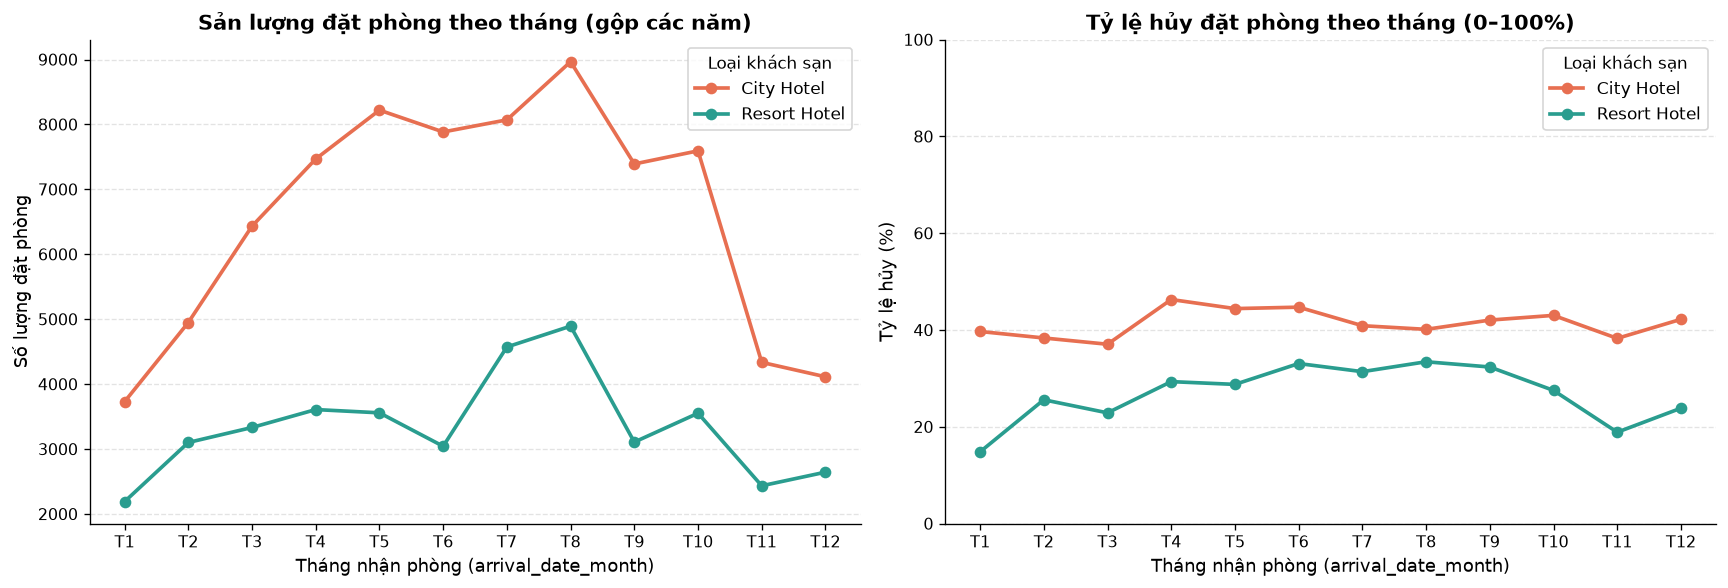

Số tháng dữ liệu có trong từng năm: {2015: 6, 2016: 12, 2017: 8}


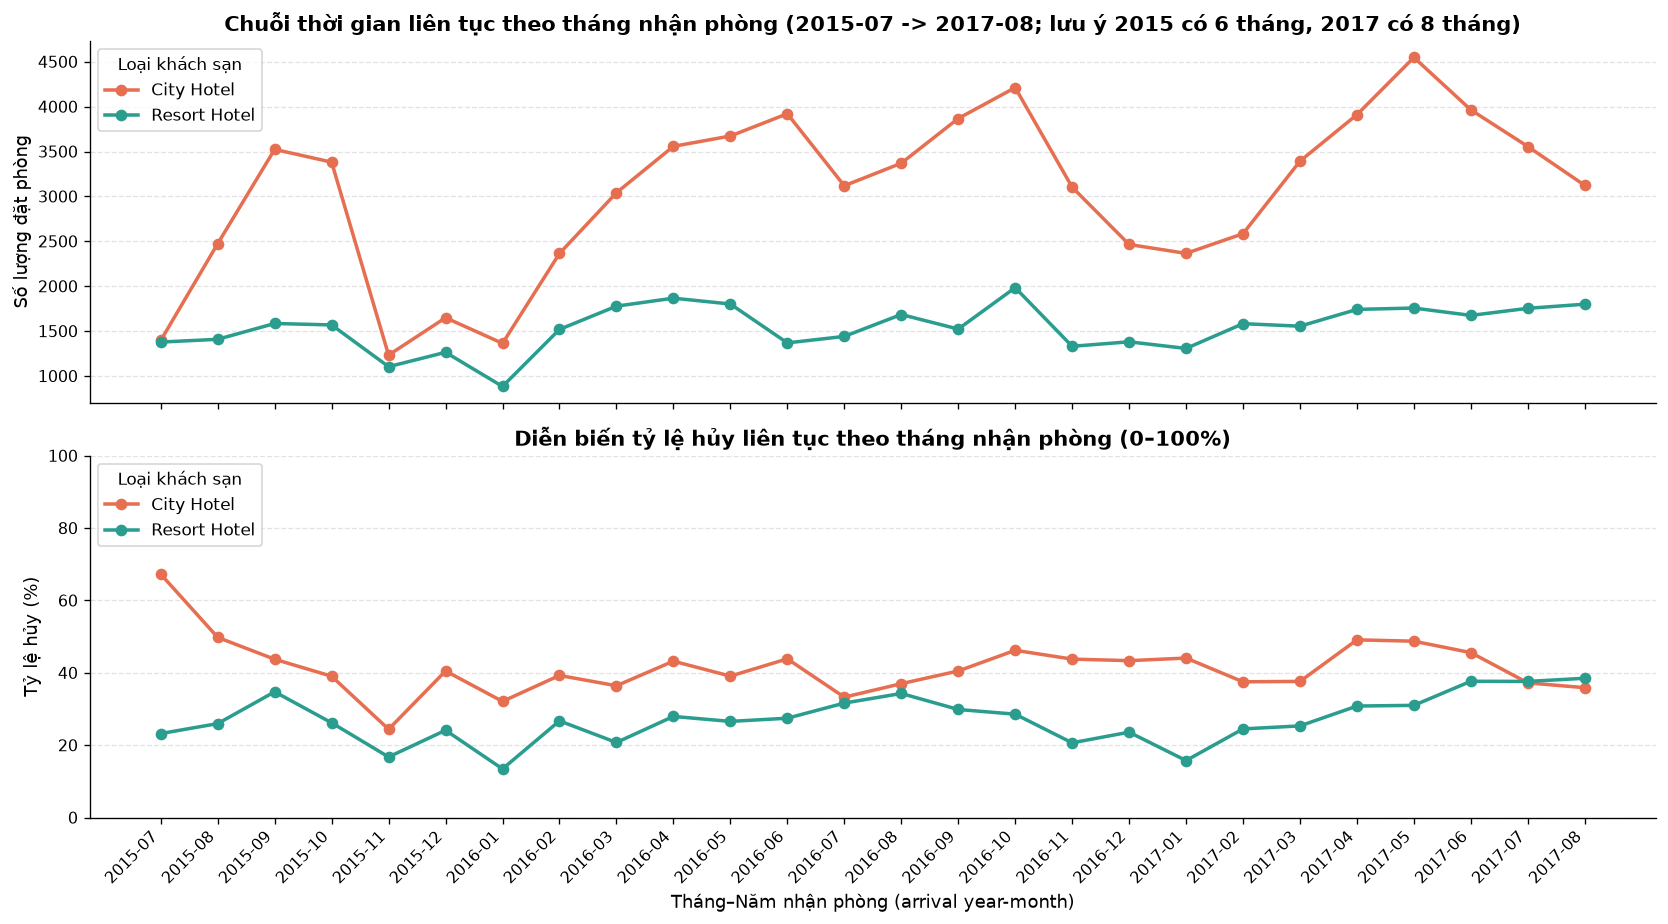

In [11]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]
month_short = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"]

arrival_eda = pd.to_datetime(
    pd.DataFrame({
        "year": df_eda["arrival_date_year"],
        "month": df_eda["arrival_date_month"].map(month_map),
        "day": df_eda["arrival_date_day_of_month"],
    }),
    errors="coerce",
)
assert arrival_eda.notna().all(), "Phát hiện arrival_date không hợp lệ trong df_eda!"

# Biểu đồ 03: Mùa vụ 12 tháng (tách rõ sản lượng và tỷ lệ hủy, reindex đủ 12 tháng)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5))
hotel_colors = {"City Hotel": "#e76f51", "Resort Hotel": "#2a9d8f"}

for hotel, color in hotel_colors.items():
    sub = df_eda[df_eda["hotel"] == hotel]
    monthly = sub.groupby("arrival_date_month")[TARGET].agg(["size", "mean"]).reindex(month_order)
    x_idx = np.arange(len(month_order))
    axes[0].plot(x_idx, monthly["size"], marker="o", linewidth=2.2, label=hotel, color=color)
    axes[1].plot(x_idx, monthly["mean"] * 100, marker="o", linewidth=2.2, label=hotel, color=color)

for ax in axes:
    ax.set_xticks(np.arange(len(month_order)))
    ax.set_xticklabels(month_short)
    ax.set_xlabel("Tháng nhận phòng (arrival_date_month)")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(title="Loại khách sạn")

axes[0].set_title("Sản lượng đặt phòng theo tháng (gộp các năm)")
axes[0].set_ylabel("Số lượng đặt phòng")
axes[1].set_title("Tỷ lệ hủy đặt phòng theo tháng (0–100%)")
axes[1].set_ylabel("Tỷ lệ hủy (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
fig.savefig(FIG_DIR / "03_seasonality_monthly_cancellation.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Biểu đồ 03b: Chuỗi thời gian liên tục theo year-month (26 tháng)
df_time = df_eda.assign(arrival_ym=arrival_eda.dt.to_period("M"))
all_months = pd.period_range(df_time["arrival_ym"].min(), df_time["arrival_ym"].max(), freq="M")
year_month_counts = df_time.groupby("arrival_date_year")["arrival_ym"].nunique().to_dict()
print("Số tháng dữ liệu có trong từng năm:", year_month_counts)

fig, axes = plt.subplots(2, 1, figsize=(14, 7.8), sharex=True)
x_pos = np.arange(len(all_months))
x_labels = [str(p) for p in all_months]

for hotel, color in hotel_colors.items():
    sub = df_time[df_time["hotel"] == hotel]
    ts = sub.groupby("arrival_ym")[TARGET].agg(["size", "mean"]).reindex(all_months)
    axes[0].plot(x_pos, ts["size"], marker="o", linewidth=2.1, label=hotel, color=color)
    axes[1].plot(x_pos, ts["mean"] * 100, marker="o", linewidth=2.1, label=hotel, color=color)

axes[0].set_title(f"Chuỗi thời gian liên tục theo tháng nhận phòng ({all_months[0]} -> {all_months[-1]}; lưu ý 2015 có {year_month_counts.get(2015, 0)} tháng, 2017 có {year_month_counts.get(2017, 0)} tháng)")
axes[0].set_ylabel("Số lượng đặt phòng")
axes[0].grid(axis="y", linestyle="--", alpha=0.35)
axes[0].legend(title="Loại khách sạn", loc="upper left")

axes[1].set_title("Diễn biến tỷ lệ hủy liên tục theo tháng nhận phòng (0–100%)")
axes[1].set_ylabel("Tỷ lệ hủy (%)")
axes[1].set_xlabel("Tháng–Năm nhận phòng (arrival year-month)")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, rotation=45, ha="right")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(title="Loại khách sạn", loc="upper left")

plt.tight_layout()
fig.savefig(FIG_DIR / "03b_continuous_monthly_trend.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Nhận xét mùa vụ & xu hướng thời gian:**
- Cả hai loại khách sạn đều thể hiện tính mùa vụ rõ rệt: sản lượng đặt phòng tăng mạnh vào mùa xuân–hè (tháng 4 đến tháng 8) và giảm vào mùa đông (tháng 11 đến tháng 2).
- Tỷ lệ hủy của `City Hotel` duy trì ở mức cao hơn `Resort Hotel` trong hầu hết 26 tháng liên tục; sang năm 2017, tỷ lệ hủy mùa hè có xu hướng nhích lên — gợi ý nên đánh giá thêm độ ổn định theo thời gian khi kiểm thử mô hình.
- Năm `2015` chỉ gồm `6` tháng (07–12/2015) và năm `2017` chỉ gồm `8` tháng (01–08/2017), do đó không so sánh trực tiếp tổng lượng đặt phòng cả năm giữa 2015, 2016 và 2017.

## 4. Kết luận EDA & Định hướng Tiền xử lý (Notebook 02)

### 4.1 Tóm tắt các phát hiện chính
1. **Dữ liệu sau làm sạch (`df_clean` / `df_eda`):** Loại bỏ `181` bản ghi không hợp lệ (`180` dòng có tổng khách = 0 khi biết đủ 3 thành phần và `1` dòng `adr < 0`), còn lại `119.209` bản ghi hợp lệ với tỷ lệ hủy `37,08%` (thay đổi `+0,04` điểm phần trăm so với dữ liệu gốc).
2. **Kiểm soát Data Leakage:** Bắt buộc loại `reservation_status` và `reservation_status_date` (rò rỉ nhãn 100%). Đối với bài toán dự đoán tại thời điểm xác nhận đặt phòng, cần cân nhắc loại thêm nhóm biến hậu đặt phòng (`assigned_room_type`, `booking_changes`, `days_in_waiting_list`) và kiểm tra nguồn ghi nhận của `deposit_type` (nhóm `Non Refund` có tỷ lệ hủy ~99,4%).
3. **Các đặc trưng nổi bật trong EDA:** `lead_time` (đặt càng sớm tỷ lệ hủy càng cao), `total_of_special_requests` (càng nhiều yêu cầu đặc biệt tỷ lệ hủy càng thấp), `hotel`, `market_segment`, `customer_type` và tính mùa vụ theo tháng nhận phòng.
4. **Tính chất phân phối & dữ liệu thiếu:** Các biến số lệch phải rõ rệt; `company` (~94,3%) và `agent` (~13,7%) thiếu nhiều nhưng thực chất là mã định danh phân loại — cần xử lý trong pipeline huấn luyện thay vì điền trung bình số học.

### 4.2 Định hướng cho bước Tiền xử lý & Ghi chú đồng bộ với `02_preprocessing_fe.ipynb`
- **Nguyên tắc chung:** Tách tập Train/Test trước khi fit mọi bộ biến đổi có tham số (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `TargetEncoder`) để tránh rò rỉ dữ liệu; giữ `target` và `features` tách biệt.
- **Các điểm chưa đồng bộ cần lưu ý với `02_preprocessing_fe.ipynb` hiện có (chưa sửa trong đợt này):**
  1. *Chính sách duplicates:* `01_eda.ipynb` giữ duplicates mặc định (và chỉ dùng `df_dedup_candidate` để so sánh độ nhạy), trong khi `02_preprocessing_fe.ipynb` hiện đang loại toàn bộ dòng trùng lặp trước khi chia tập.
  2. *Xử lý ngoại lai `adr > 1000` và `children = NA`:* `01_eda.ipynb` giữ `adr = 5400` và trì hoãn `children = NA`, trong khi `02_preprocessing_fe.ipynb` hiện đang loại `adr > 1000` và điền `children = 0` trước khi chia tập.
  3. *Nhóm biến hậu đặt phòng:* `02_preprocessing_fe.ipynb` hiện giữ `assigned_room_type`, `room_type_changed`, `booking_changes`, `days_in_waiting_list` theo chuẩn Kaggle benchmark; nếu chuyển sang dự đoán chặt chẽ tại thời điểm xác nhận đặt phòng thì cần loại các biến này ở bước cập nhật Notebook 02 tiếp theo.